# FIREGUARD ID v2 — Minggu 5: [O] Optimization Deep Learning (DEC)
**Sesuai Ketentuan Minggu 5 (Bab 6.3.4–6.3.7):** Konfigurasi training, >=2 eksperimen optimasi, >=10 epoch dengan GPU/CPU & runtime, plot kurva loss per epoch, diagnosis konvergensi, dan ringkasan checkpoint.

In [1]:
import os, sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

import json
import numpy as np
import pandas as pd
from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print("Repo root:", REPO_ROOT)

Repo root: FIREGUARD-ID


In [2]:
dec_exp = json.loads(resolve_path("reports/clustering/dec_experiments.json", REPO_ROOT).read_text(encoding="utf-8"))
sel = dec_exp["selected_model"]
print("Device:", dec_exp["device"], "| Runtime (s):", sel["runtime_seconds"])
print("Pretrain MSE:", sel["pretrain_summary"]["initial_mse"], "->", sel["pretrain_summary"]["final_mse"], f"({len(sel['pretrain_summary']['history_full'])} epochs)")
print("Finetune converged:", sel["finetune_convergence"]["converged"], "| Epochs:", sel["finetune_convergence"]["epochs_run"], "| Stop:", sel["finetune_convergence"]["stop_reason"])

print("\nOptimization Experiments Comparison:")
display(pd.DataFrame(dec_exp["optimization_experiments"]))

Device: {'type': 'cuda', 'name': 'NVIDIA GeForce RTX 4050 Laptop GPU'} | Runtime (s): 11.0475
Pretrain MSE: 1.057939 -> 0.000843 (120 epochs)
Finetune converged: True | Epochs: 200 | Stop: delta_label (0.000000) < tol (0.001)

Optimization Experiments Comparison:


,experiment_name,finetune_lr,batch_size,gamma_recon,epochs_run,converged,runtime_seconds,final_kl_loss,final_recon_mse,final_total_loss,silhouette_feature,davies_bouldin_feature,silhouette_latent,ari_vs_selected
0,opt_baseline_lr5e4_bs64_g01,0.0005,64,0.1,200,True,11.0475,0.047777,0.019528,0.049730,0.480230,0.847784,0.877686,1.000000
1,opt_high_lr1e3_bs64_g01,0.0010,64,0.1,140,True,13.7721,0.038562,0.056268,0.044188,0.504972,0.822865,0.904778,0.922067
2,opt_pure_kl_lr5e4_bs32_g00,0.0005,32,0.0,160,True,24.8295,0.037203,1.425550,0.037203,0.504875,0.825589,0.910094,0.900680


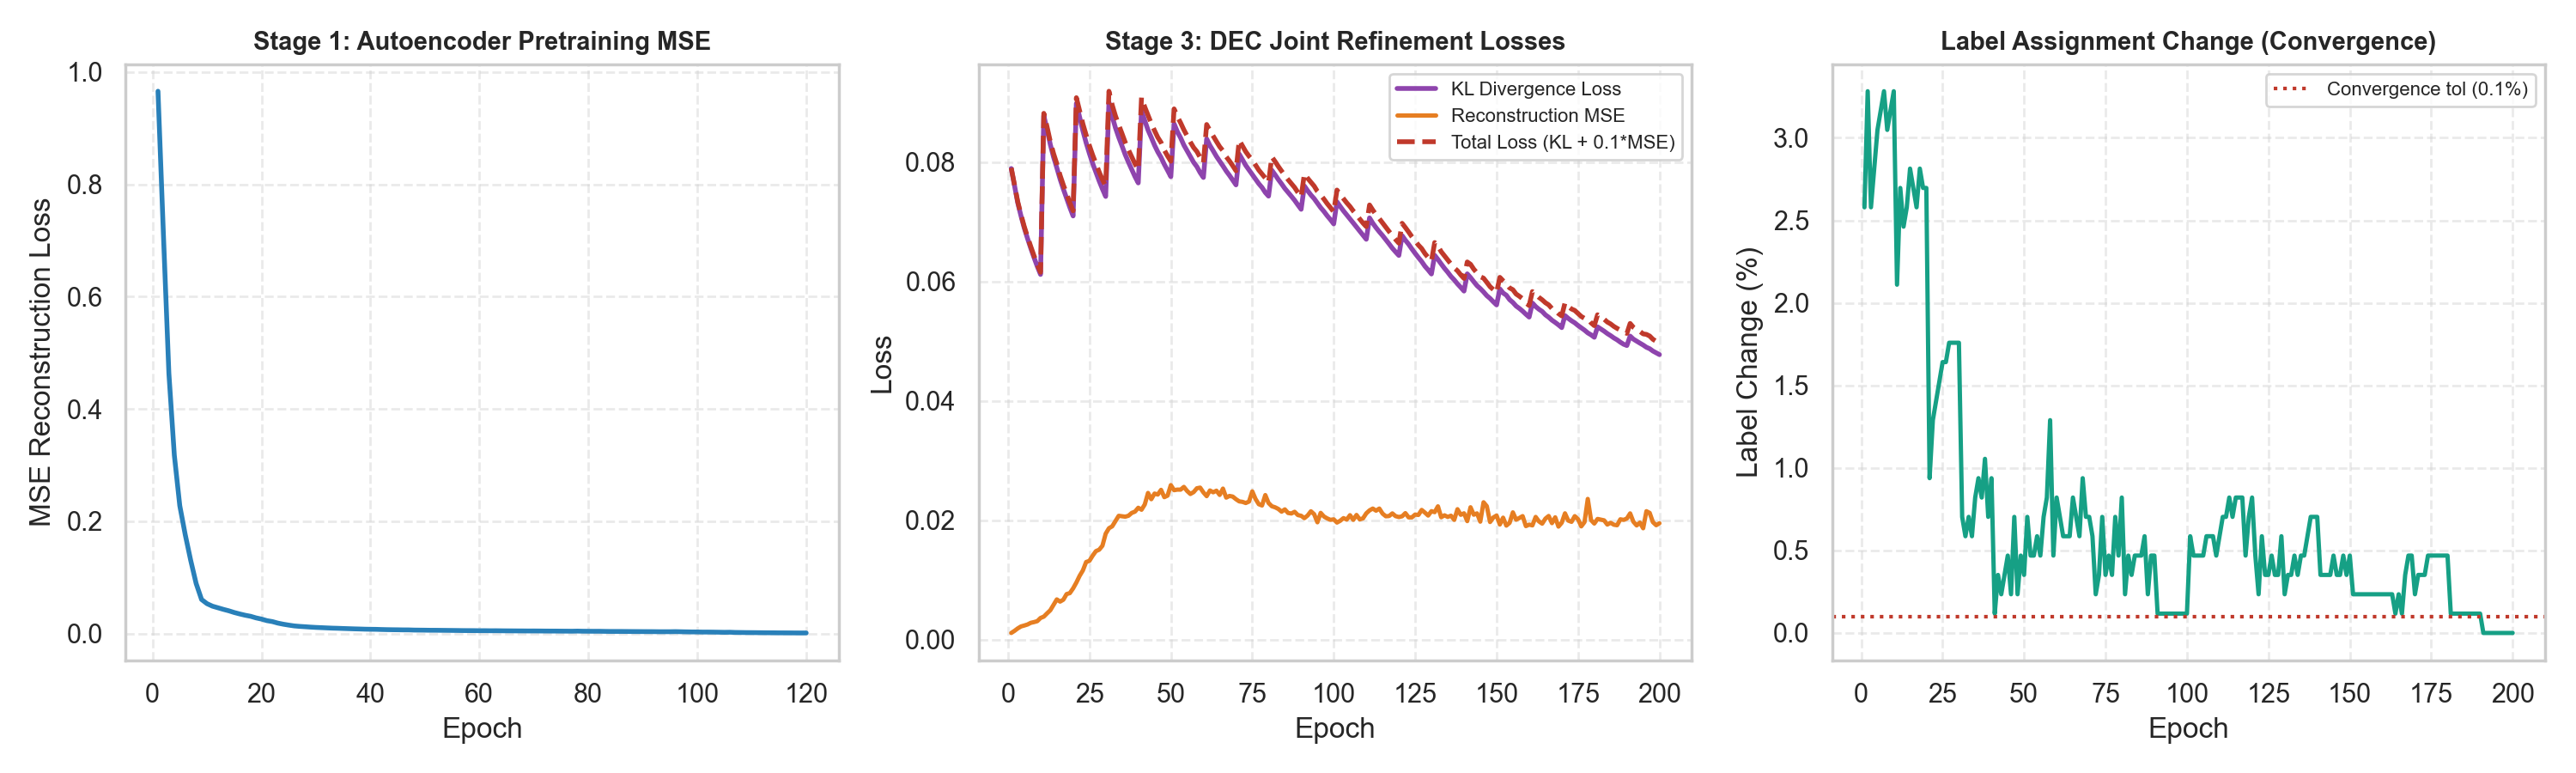

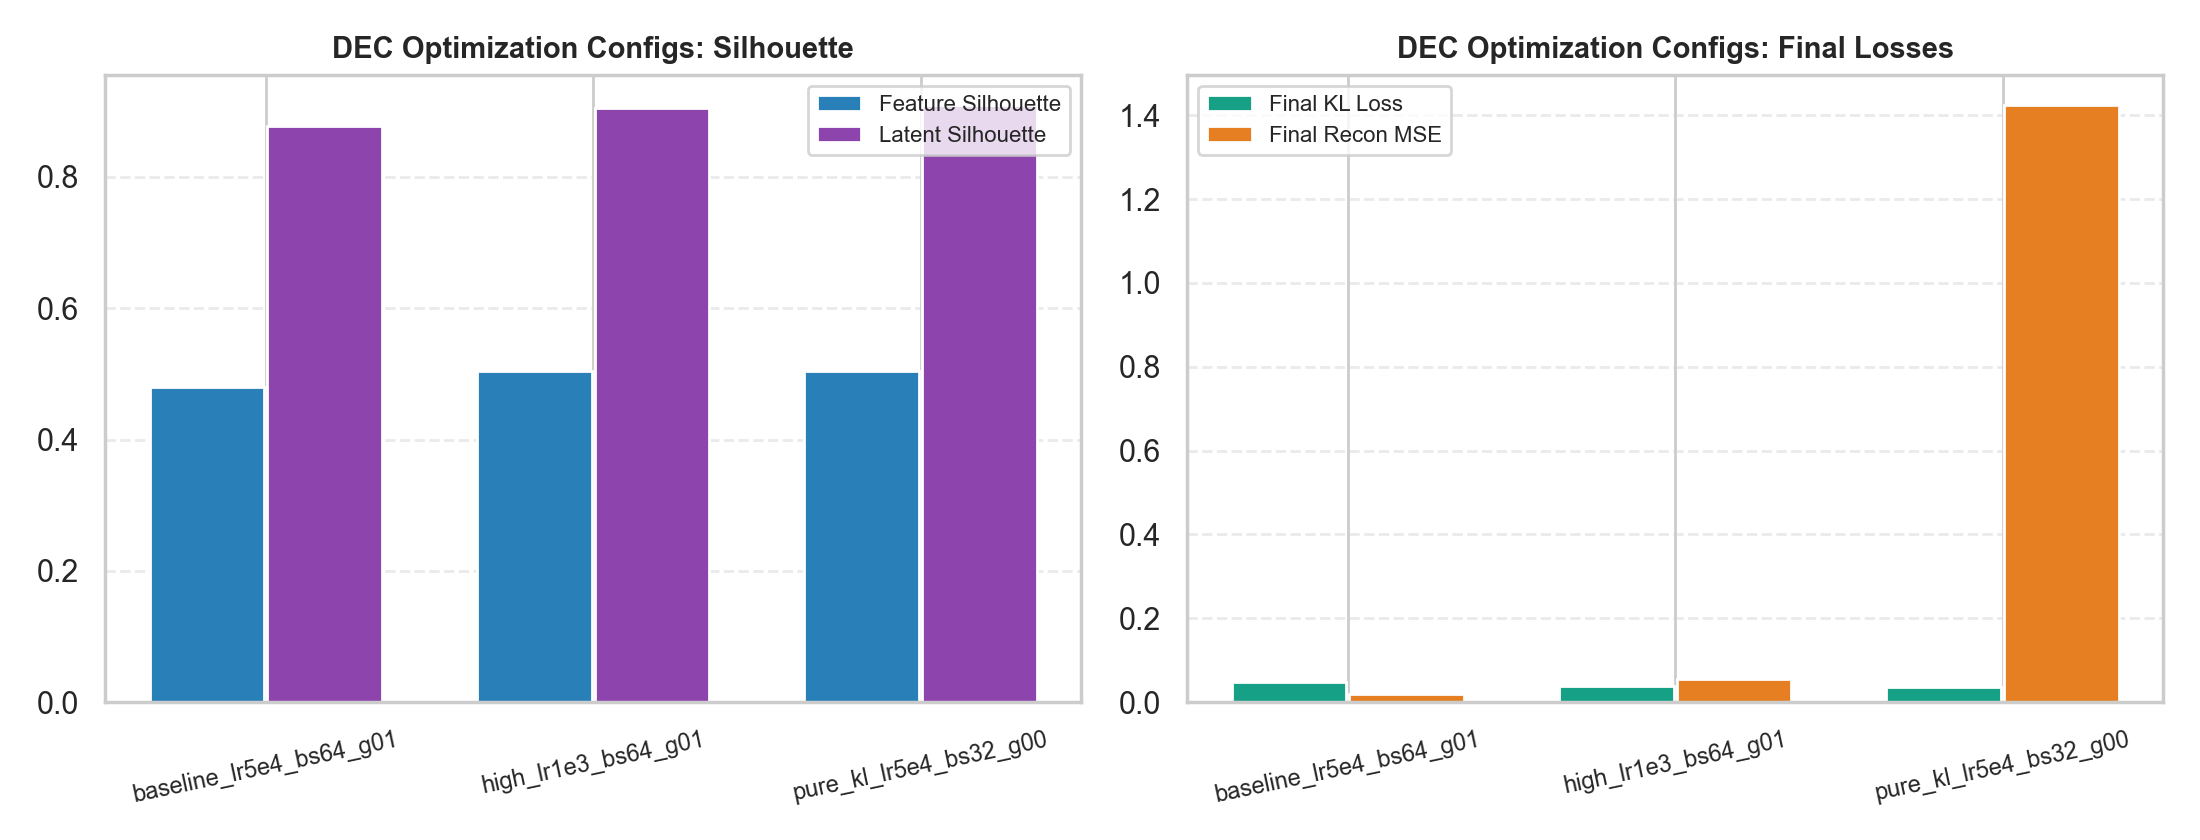

In [3]:
from IPython.display import Image, display as ipy_display
ipy_display(Image(filename=str(resolve_path("reports/clustering/dec_training_history.png", REPO_ROOT))))
ipy_display(Image(filename=str(resolve_path("reports/clustering/dec_optimization_comparison.png", REPO_ROOT))))